# Predicción del tabaquismo y del consumo de alcohol mediante aprendizaje automático a partir de variables antropométricas y clínicas

Integrantes:

Juan Esteban Agudelo Berrio

Jerónimo Betancur Álvarez

Juan Manuel Ocampo López

Usamos el conjunto de datos Smoking and Drinking Dataset with Body Signal (Kaggle, https://www.kaggle.com/datasets/sooyoungher/smoking-drinking-dataset) para predecir, a partir de datos de chequeos médicos, el estado de tabaquismo (3 clases) y el consumo de alcohol (sí o no). Cada fase explica qué hacemos y por qué, y termina con una verificación.

Para volver a ejecutar los experimentos, sigue el orden del README. Si solo quieres ver qué obtuvimos, puedes leer las salidas guardadas. Las cifras corresponden al archivo completo. La muestra del 2 % sirve para revisar la preparación de datos.

## Fase #0: Preparación

Instalamos la librería para estratificar con varias salidas y cargamos las demás. El archivo es el del dataset de Kaggle (991.346 filas y 24 columnas).

Usamos Colab con el directorio de trabajo `/content`. Ejecuta la instalación, los imports y la carga del CSV en ese orden. Los resultados se guardan en el espacio temporal de Colab, de donde puedes descargarlos al terminar. El primer control es que el archivo cargado tenga **991.346 filas y 24 columnas**.

In [ ]:
# Librerias necesarias
!pip install iterative-stratification gdown
!pip -q install umap-learn

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,matthews_corrcoef, roc_auc_score, precision_recall_fscore_support)
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
from sklearn.decomposition import PCA
from sklearn.preprocessing import FunctionTransformer
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import umap
import warnings
import json
import os
import numpy as np
import pandas as pd
import pandas as pd
import gdown
import time

In [ ]:
# Importamos el dataset desde drive
file_id = '1CICG7oXP4IiECDiP2rm7qf_BiJDL0eMe'
output_name = 'smoking_driking_dataset_VerOriginal.csv'

gdown.download(id=file_id, output=output_name, quiet=False)
df = pd.read_csv("smoking_driking_dataset_VerOriginal.csv")
df.head()

Downloading...
From (original): https://drive.google.com/uc?id=1CICG7oXP4IiECDiP2rm7qf_BiJDL0eMe
From (redirected): https://drive.google.com/uc?id=1CICG7oXP4IiECDiP2rm7qf_BiJDL0eMe&confirm=t&uuid=29ed9ad0-ca0b-4800-b91e-951b30ba8855
To: /content/smoking_driking_dataset_VerOriginal.csv
100%|██████████| 110M/110M [00:01<00:00, 94.8MB/s]


,sex,age,height,weight,waistline,sight_left,sight_right,hear_left,hear_right,SBP,...,LDL_chole,triglyceride,hemoglobin,urine_protein,serum_creatinine,SGOT_AST,SGOT_ALT,gamma_GTP,SMK_stat_type_cd,DRK_YN
0,Male,35,170,75,90.0,1.0,1.0,1.0,1.0,120.0,...,126.0,92.0,17.1,1.0,1.0,21.0,35.0,40.0,1.0,Y
1,Male,30,180,80,89.0,0.9,1.2,1.0,1.0,130.0,...,148.0,121.0,15.8,1.0,0.9,20.0,36.0,27.0,3.0,N
2,Male,40,165,75,91.0,1.2,1.5,1.0,1.0,120.0,...,74.0,104.0,15.8,1.0,0.9,47.0,32.0,68.0,1.0,N
3,Male,50,175,80,91.0,1.5,1.2,1.0,1.0,145.0,...,104.0,106.0,17.6,1.0,1.1,29.0,34.0,18.0,1.0,N
4,Male,50,165,60,80.0,1.0,1.2,1.0,1.0,138.0,...,117.0,104.0,13.8,1.0,0.8,19.0,12.0,25.0,1.0,N


## Fase #1: Datos y limpieza

Limpiamos con reglas fijas que no dependen de los datos de entrenamiento o prueba, así que se pueden aplicar antes de partir sin fuga de información. Quitamos duplicados y valores imposibles (por ejemplo, cintura de 999 cm o HDL mayor que el colesterol total). Los umbrales de colesterol total (500) y creatinina (15) son decisiones nuestras, no normas clínicas. En la visión, 9.9 significa ceguera según el autor del dataset, así que lo cambiamos a 0.0 y dejamos una columna indicadora.

In [ ]:
n0 = len(df)
df = df.drop_duplicates()

TOT_MAX   = 500   # colesterol total
CREAT_MAX = 15    # creatinina

# LDL esperado a partir de las otras columnas (fórmula de Friedewald)
ldl_calc = df["tot_chole"] - df["HDL_chole"] - df["triglyceride"] / 5

errores = (
    (df["waistline"] == 999) |
    (df["HDL_chole"] > df["tot_chole"]) |
    (df["LDL_chole"] > df["tot_chole"]) |
    ((df["LDL_chole"] <= 5) & (ldl_calc > 20)) |
    (df["tot_chole"] >= TOT_MAX) |
    (df["serum_creatinine"] >= CREAT_MAX)
)
print("Filas eliminadas por valores imposibles:", errores.sum())
df = df[~errores].copy()

df["sight_left_cod"]  = (df["sight_left"]  == 9.9).astype(int)
df["sight_right_cod"] = (df["sight_right"] == 9.9).astype(int)
df.loc[df["sight_left"]  == 9.9, "sight_left"]  = 0.0
df.loc[df["sight_right"] == 9.9, "sight_right"] = 0.0

df["sex"] = (df["sex"] == "Male").astype(int)
y_tabaco  = df["SMK_stat_type_cd"].astype(int)
y_alcohol = (df["DRK_YN"] == "Y").astype(int)
X = df.drop(columns=["SMK_stat_type_cd", "DRK_YN"])

print("Filas antes/después:", n0, "->", len(df))
print("X:", X.shape, "| nulos:", int(X.isnull().sum().sum()))
print("tot_chole máx:", X.tot_chole.max(), "| creatinina máx:", X.serum_creatinine.max(), "| sight máx:", X.sight_left.max())
print("Tabaquismo:", y_tabaco.value_counts().sort_index().to_dict(), "| Alcohol:", y_alcohol.value_counts().sort_index().to_dict())

Filas eliminadas por valores imposibles: 315
Filas antes/después: 991346 -> 991005
X: (991005, 24) | nulos: 0
tot_chole máx: 497.0 | creatinina máx: 14.7 | sight máx: 2.5
Tabaquismo: {1: 602256, 2: 174900, 3: 213849} | Alcohol: {0: 495674, 1: 495331}


## Fase #2: Partición entrenamiento / prueba

Apartamos el 20 % de los datos como conjunto de prueba, que no se toca hasta la evaluación final. Como hay dos salidas, estratificamos con iterative-stratification para que las proporciones de las dos se mantengan en ambas partes.

In [ ]:
SEED = 42          # semilla única para todo el notebook
TEST_SIZE = 0.20

# Matriz de etiquetas: tabaquismo en one-hot (3 columnas) + alcohol (1 columna)
# y_tabaco va de 1 a 3, por eso se resta 1 para indexar
Y_ind = np.column_stack([np.eye(3, dtype=int)[y_tabaco.values - 1], y_alcohol.values])

msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
idx_ent, idx_test = next(msss.split(X, Y_ind))

X_ent,  X_test  = X.iloc[idx_ent],         X.iloc[idx_test]
yt_ent, yt_test = y_tabaco.iloc[idx_ent],  y_tabaco.iloc[idx_test]
ya_ent, ya_test = y_alcohol.iloc[idx_ent], y_alcohol.iloc[idx_test]
print("Entrenamiento:", len(X_ent), "| Prueba:", len(X_test))

# --- Verificación: ¿se conservaron las proporciones? ---
def resumen(yt, ya):
    comb = (yt.astype(str) + "-" + ya.astype(str)).value_counts(normalize=True).sort_index()
    return pd.concat([
        yt.value_counts(normalize=True).sort_index().rename(lambda k: f"tabaco={k}"),
        ya.value_counts(normalize=True).sort_index().rename(lambda k: f"alcohol={k}"),
        comb.rename(lambda k: f"comb {k}")])

tabla = pd.DataFrame({"total":  resumen(y_tabaco, y_alcohol),
                      "entren": resumen(yt_ent, ya_ent),
                      "prueba": resumen(yt_test, ya_test)})
print((tabla * 100).round(3))
print("Sin solapamiento:", len(set(idx_ent) & set(idx_test)) == 0, "| Cubren todo:", len(idx_ent) + len(idx_test) == len(X))

Entrenamiento: 792804 | Prueba: 198201
            total  entren  prueba
tabaco=1   60.772  60.772  60.772
tabaco=2   17.649  17.649  17.649
tabaco=3   21.579  21.579  21.579
alcohol=0  50.017  50.017  50.017
alcohol=1  49.983  49.983  49.983
comb 1-0   39.240  39.241  39.236
comb 1-1   21.532  21.531  21.536
comb 2-0    5.495   5.492   5.508
comb 2-1   12.154  12.157  12.141
comb 3-0    5.282   5.284   5.273
comb 3-1   16.297  16.295  16.306
Sin solapamiento: True | Cubren todo: True


## Fase #3: Preprocesamiento y métricas

Aquí definimos cómo escalar las entradas y cómo comparar los modelos. Las mismas funciones de evaluación se vuelven a usar en la prueba final.

### Fase #3.1: Fuga de datos y escalado

Escalamos las variables con RobustScaler, que usa la mediana y el rango intercuartílico, así que los valores extremos que conservamos le afectan poco. El escalador aprende solo de los datos de entrenamiento para no filtrar información de la prueba, y por eso va dentro de un Pipeline.





In [ ]:
#Aquí un ejemplo de cómo se armará cada modelo que necesite escalado.
pipe_prueba = Pipeline([
    ("escalado", RobustScaler()),
    ("modelo", LogisticRegression(max_iter=500)),
])
pipe_prueba.fit(X_ent.iloc[:50000], yt_ent.iloc[:50000])

# Qué aprendió el escalador (solo con esas filas de entrenamiento)
esc = pipe_prueba.named_steps["escalado"]
resumen_esc = pd.DataFrame({"mediana": esc.center_, "IQR": esc.scale_}, index=X_ent.columns)
print(resumen_esc.round(2))

                  mediana   IQR
sex                   1.0   1.0
age                  45.0  25.0
height              160.0  15.0
weight               60.0  15.0
waistline            81.0  13.6
sight_left            1.0   0.5
sight_right           1.0   0.5
hear_left             1.0   1.0
hear_right            1.0   1.0
SBP                 120.0  19.0
DBP                  76.0  12.0
BLDS                 96.0  17.0
tot_chole           193.5  50.0
HDL_chole            55.0  20.0
LDL_chole           111.0  46.0
triglyceride        106.0  84.0
hemoglobin           14.3   2.2
urine_protein         1.0   1.0
serum_creatinine      0.8   0.3
SGOT_AST             23.0   9.0
SGOT_ALT             20.0  15.0
gamma_GTP            23.0  23.0
sight_left_cod        0.0   1.0
sight_right_cod       0.0   1.0


In [ ]:
#Codigo reutilizable
def con_escalado(modelo):
    """Envuelve un modelo en un Pipeline con RobustScaler.
    El escalador se ajusta solo con los datos que reciba fit (sin fuga de información)."""
    return Pipeline([("escalado", RobustScaler()), ("modelo", modelo)])

### Fase #3.2: Definición de métricas

En tabaquismo la exactitud sola engaña, ya que un modelo que siempre diga "nunca fumó" acierta el 60,8 %. Por eso medimos también exactitud balanceada, F1 macro, MCC y AUC, y miramos cada clase por separado. Para alcohol, que está casi 50/50, usamos exactitud, F1, AUC y MCC.

In [ ]:
def evaluar_tabaco(y_real, y_pred, y_proba):
    """y_real/y_pred en {1,2,3}; y_proba: matriz (n, 3), columnas en orden de clases 1,2,3."""
    res = {
        "exactitud": accuracy_score(y_real, y_pred),
        "exactitud_balanceada": balanced_accuracy_score(y_real, y_pred),
        "F1_macro": f1_score(y_real, y_pred, average="macro"),
        "MCC": matthews_corrcoef(y_real, y_pred),
        "AUC_ovr_macro": roc_auc_score(y_real, y_proba, multi_class="ovr", average="macro", labels=[1, 2, 3]),
    }
    p, r, f, _ = precision_recall_fscore_support(y_real, y_pred, labels=[1, 2, 3], zero_division=0)
    por_clase = pd.DataFrame({"precision": p, "sensibilidad": r, "F1": f}, index=["1 nunca", "2 exfumador", "3 fuma"])
    return res, por_clase

def evaluar_alcohol(y_real, y_pred, y_score):
    """y_real/y_pred en {0,1}; y_score: probabilidad de la clase 1 (vector)."""
    return {
        "exactitud": accuracy_score(y_real, y_pred),
        "F1": f1_score(y_real, y_pred),
        "AUC": roc_auc_score(y_real, y_score),
        "MCC": matthews_corrcoef(y_real, y_pred),
    }

print("Funciones de evaluación definidas.")

Funciones de evaluación definidas.


## Fase #4: Modelos base independientes

Entrenamos las cinco familias de modelos de la guía con hiperparámetros por defecto o de partida, una vez por cada tarea. Para compararlos partimos el entrenamiento en uno interno (80 %) y una validación (20 %), así el conjunto de prueba sigue sin usarse. Es una primera mirada de una sola corrida; los intervalos de confianza vienen con la validación cruzada de la fase 6 que veremos después.

### Fase #4.1: Validación interna y submuestras

KNN y la SVM son costosos con casi 800 mil filas. A la SVM la entrenamos con una submuestra estratificada de 20 mil filas. A KNN le medimos primero el tiempo, y como salió manejable lo corrimos con todo el entrenamiento interno.

In [ ]:
Y_ind_ent = Y_ind[idx_ent]          # matriz de etiquetas de las filas de entrenamiento

msss_val = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
i_fit, i_val = next(msss_val.split(X_ent, Y_ind_ent))

X_fit,  X_val  = X_ent.iloc[i_fit],  X_ent.iloc[i_val]
yt_fit, yt_val = yt_ent.iloc[i_fit], yt_ent.iloc[i_val]
ya_fit, ya_val = ya_ent.iloc[i_fit], ya_ent.iloc[i_val]
Y_ind_fit = Y_ind_ent[i_fit]

def submuestra(n, semilla=SEED):
    """Submuestra estratificada (multi-salida) de n filas del entrenamiento interno."""
    s = MultilabelStratifiedShuffleSplit(n_splits=1, train_size=n, test_size=None, random_state=semilla)
    idx, _ = next(s.split(X_fit, Y_ind_fit))
    return X_fit.iloc[idx], yt_fit.iloc[idx], ya_fit.iloc[idx]

# ---- Verificación ----
Xs, yts, yas = submuestra(20_000)
def prop(yt, ya):
    return pd.Series({**{f"tabaco={k}": v for k, v in yt.value_counts(normalize=True).sort_index().items()}, "alcohol=1": ya.mean()})
print("Filas -> fit:", len(X_fit), "| val:", len(X_val), "| submuestra:", len(Xs))
print((pd.DataFrame({"fit": prop(yt_fit, ya_fit), "val": prop(yt_val, ya_val), "submuestra": prop(yts, yas)}) * 100).round(2))
print("Sin solapamiento fit/val:", not (set(X_fit.index) & set(X_val.index)), "| submuestra dentro de fit:", set(Xs.index) <= set(X_fit.index))

Filas -> fit: 634243 | val: 158561 | submuestra: 20000
             fit    val  submuestra
tabaco=1   60.77  60.77       60.77
tabaco=2   17.65  17.65       17.65
tabaco=3   21.58  21.58       21.58
alcohol=1  49.98  49.98       49.98
Sin solapamiento fit/val: True | submuestra dentro de fit: True


### Fase #4.2: Entrenamiento de modelos:


In [ ]:
# tabla_resultados ES donde cada modelo guardara sus métricas para así armar la comparación al final
tabla_resultados = []

def registrar(nombre, tarea, res, segundos):
    tabla_resultados.append({"modelo": nombre, "tarea": tarea, **res, "segundos": round(segundos, 1)})


In [ ]:
# Referencia tabaquismo: siempre predice según la proporción de clases del entrenamiento
ref = DummyClassifier(strategy="prior").fit(X_fit, yt_fit)
res_ref, _ = evaluar_tabaco(yt_val, ref.predict(X_val), ref.predict_proba(X_val))
registrar("Referencia (siempre la clase mayoritaria)", "tabaco", res_ref, 0)

In [ ]:
#Sección de consumo de alcohol
def evaluar_alc_modelo(nombre, modelo, seg_entrenamiento=0.0):
    """Predice sobre toda la validación, evalúa y registra (segundos = entrenamiento + predicción)."""
    t = time.time()
    proba = modelo.predict_proba(X_val)[:, 1]
    pred = (proba >= 0.5).astype(int)
    seg_pred = time.time() - t
    res = evaluar_alcohol(ya_val, pred, proba)
    registrar(nombre, "alcohol", res, seg_entrenamiento + seg_pred)

# Referencia consumo de alcohol: siempre predice según la proporción de clases del entrenamiento
ref_a = DummyClassifier(strategy="prior").fit(X_fit, ya_fit)
registrar("Referencia (siempre la clase mayoritaria)", "alcohol", evaluar_alcohol(ya_val, ref_a.predict(X_val), ref_a.predict_proba(X_val)[:, 1]), 0)

A) Regresión logística

A.1) Tabaquismo

In [ ]:
#Primero escalamos
t = time.time()
lr_tabaco = con_escalado(LogisticRegression(max_iter=1000)).fit(X_fit, yt_fit)
seg = time.time() - t
res_lr, clase_lr = evaluar_tabaco(yt_val, lr_tabaco.predict(X_val), lr_tabaco.predict_proba(X_val))
registrar("Regresión logística", "tabaco", res_lr, seg)

print(pd.DataFrame(tabla_resultados).round(3).to_string(index=False))
print()
print(clase_lr.round(3))
print("Clases del modelo:", lr_tabaco.classes_)

                                   modelo  tarea  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria) tabaco      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística tabaco      0.681                 0.591     0.584 0.435          0.831       0.0

             precision  sensibilidad     F1
1 nunca          0.833         0.796  0.814
2 exfumador      0.443         0.351  0.391
3 fuma           0.483         0.626  0.546
Clases del modelo: [1 2 3]


A.2) Consumo de alcohol

In [ ]:
t = time.time()
lr_alc = con_escalado(LogisticRegression(max_iter=1000)).fit(X_fit, ya_fit)
seg = time.time() - t
evaluar_alc_modelo("Regresión logística", lr_alc, seg)

tabla_alc = pd.DataFrame(tabla_resultados)
print(tabla_alc[tabla_alc["tarea"] == "alcohol"].round(3).to_string(index=False))

                                   modelo   tarea  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos    F1   AUC
Referencia (siempre la clase mayoritaria) alcohol      0.500                   NaN       NaN 0.000            NaN       0.0 0.000 0.500
                      Regresión logística alcohol      0.722                   NaN       NaN 0.445            NaN       3.2 0.722 0.796


B) Random forest

B.1) Tabaquismo

In [ ]:
t = time.time()
rf_tabaco = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(X_fit, yt_fit)
seg = time.time() - t
res_rf, clase_rf = evaluar_tabaco(yt_val, rf_tabaco.predict(X_val), rf_tabaco.predict_proba(X_val))
registrar("Random forest", "tabaco", res_rf, seg)

print(pd.DataFrame(tabla_resultados).round(3).to_string(index=False))
print()
print(clase_rf.round(3))
imp = pd.Series(rf_tabaco.feature_importances_, index=X_fit.columns).sort_values(ascending=False)
print()
print(imp.head(8).round(3))

                                   modelo  tarea  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria) tabaco      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística tabaco      0.681                 0.591     0.584 0.435          0.831       0.0
                            Random forest tabaco      0.696                 0.600     0.597 0.455          0.843     181.8

             precision  sensibilidad     F1
1 nunca          0.839         0.824  0.831
2 exfumador      0.443         0.379  0.408
3 fuma           0.511         0.597  0.551

sex             0.196
height          0.102
hemoglobin      0.098
gamma_GTP       0.075
triglyceride    0.047
age             0.045
waistline       0.042
weight          0.042
dtype: float64


B.2) Consumo de alcohol

In [ ]:
t = time.time()
rf_alc = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                n_jobs=-1, random_state=SEED).fit(X_fit, ya_fit)
seg = time.time() - t
evaluar_alc_modelo("Random forest", rf_alc, seg)

tabla_alc = pd.DataFrame(tabla_resultados)
print(tabla_alc[tabla_alc["tarea"] == "alcohol"].drop(columns="tarea").round(3).to_string(index=False))
imp = pd.Series(rf_alc.feature_importances_, index=X_fit.columns).sort_values(ascending=False)
print()
print(imp.head(8).round(3))

                                   modelo  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos    F1   AUC
Referencia (siempre la clase mayoritaria)      0.500                   NaN       NaN 0.000            NaN       0.0 0.000 0.500
                      Regresión logística      0.722                   NaN       NaN 0.445            NaN       3.2 0.722 0.796
                            Random forest      0.731                   NaN       NaN 0.462            NaN     183.2 0.734 0.810

gamma_GTP       0.108
age             0.093
sex             0.087
height          0.084
hemoglobin      0.074
HDL_chole       0.064
triglyceride    0.050
SGOT_ALT        0.047
dtype: float64


C) KNN

C.1) Tabaquismo

In [ ]:
#KNN si requiere escalado, así que lo hacemos
knn_tabaco = con_escalado(KNeighborsClassifier(n_neighbors=25, n_jobs=-1)).fit(X_fit, yt_fit)

n_prueba = 10_000
t = time.time()
proba_10k = knn_tabaco.predict_proba(X_val.iloc[:n_prueba])
seg_10k = time.time() - t
estimado = seg_10k * len(X_val) / n_prueba
print(f"Predecir {n_prueba} filas de validación: {seg_10k:.1f} s")
print(f"Estimado para toda la validación ({len(X_val)} filas): {estimado/60:.1f} min")

Predecir 10000 filas de validación: 48.5 s
Estimado para toda la validación (158561 filas): 12.8 min


In [ ]:
t = time.time()
proba_knn = knn_tabaco.predict_proba(X_val)
seg = time.time() - t
pred_knn = knn_tabaco.classes_[proba_knn.argmax(axis=1)]

res_knn, clase_knn = evaluar_tabaco(yt_val, pred_knn, proba_knn)
registrar("KNN (k=25)", "tabaco", res_knn, seg)

print(pd.DataFrame(tabla_resultados).round(3).to_string(index=False))
print()
print(clase_knn.round(3))

                                   modelo  tarea  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria) tabaco      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística tabaco      0.681                 0.591     0.584 0.435          0.831       0.0
                            Random forest tabaco      0.696                 0.600     0.597 0.455          0.843     181.8
                               KNN (k=25) tabaco      0.675                 0.557     0.560 0.400          0.820     761.4

             precision  sensibilidad     F1
1 nunca          0.800         0.834  0.817
2 exfumador      0.402         0.335  0.366
3 fuma           0.494         0.502  0.498


C.2) Consumo de alcohol

In [ ]:
knn_alc = con_escalado(KNeighborsClassifier(n_neighbors=25, n_jobs=-1)).fit(X_fit, ya_fit)
evaluar_alc_modelo("KNN (k=25)", knn_alc)

tabla_alc = pd.DataFrame(tabla_resultados)
print(tabla_alc[tabla_alc["tarea"] == "alcohol"].drop(columns="tarea").round(3).to_string(index=False))

                                   modelo  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos    F1   AUC
Referencia (siempre la clase mayoritaria)      0.500                   NaN       NaN 0.000            NaN       0.0 0.000 0.500
                      Regresión logística      0.722                   NaN       NaN 0.445            NaN       3.2 0.722 0.796
                            Random forest      0.731                   NaN       NaN 0.462            NaN     183.2 0.734 0.810
                               KNN (k=25)      0.712                   NaN       NaN 0.425            NaN     753.1 0.719 0.787


D) Red neuronal

D.1) Tabaquismo

In [ ]:
t = time.time()
mlp_tabaco = con_escalado(MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, n_iter_no_change=5, max_iter=100, random_state=SEED)).fit(X_fit, yt_fit)
seg = time.time() - t
mlp = mlp_tabaco.named_steps["modelo"]
print("Épocas entrenadas:", mlp.n_iter_, "| segundos por época:", round(seg / mlp.n_iter_, 1))

res_mlp, clase_mlp = evaluar_tabaco(yt_val, mlp_tabaco.predict(X_val), mlp_tabaco.predict_proba(X_val))
registrar("Red neuronal (MLP 64-32)", "tabaco", res_mlp, seg)

print(pd.DataFrame(tabla_resultados).round(3).to_string(index=False))
print()
print(clase_mlp.round(3))

Épocas entrenadas: 12 | segundos por época: 3.3
                                   modelo  tarea  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria) tabaco      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística tabaco      0.681                 0.591     0.584 0.435          0.831       0.0
                            Random forest tabaco      0.696                 0.600     0.597 0.455          0.843     181.8
                               KNN (k=25) tabaco      0.675                 0.557     0.560 0.400          0.820     761.4
                 Red neuronal (MLP 64-32) tabaco      0.701                 0.611     0.608 0.465          0.847      39.9

             precision  sensibilidad     F1
1 nunca          0.843         0.823  0.833
2 exfumador      0.442         0.443  0.443
3 fuma           0.531         0.566  0.548


D.2) Consumo de alcohol

In [ ]:
t = time.time()
mlp_alc = con_escalado(MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                     n_iter_no_change=5, max_iter=100,
                                     random_state=SEED)).fit(X_fit, ya_fit)
seg = time.time() - t
print("Épocas entrenadas:", mlp_alc.named_steps["modelo"].n_iter_)
evaluar_alc_modelo("Red neuronal (MLP 64-32)", mlp_alc, seg)

tabla_alc = pd.DataFrame(tabla_resultados)
print(tabla_alc[tabla_alc["tarea"] == "alcohol"].drop(columns="tarea").round(3).to_string(index=False))

Épocas entrenadas: 10
                                   modelo  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos    F1   AUC
Referencia (siempre la clase mayoritaria)      0.500                   NaN       NaN 0.000            NaN       0.0 0.000 0.500
                      Regresión logística      0.722                   NaN       NaN 0.445            NaN       3.2 0.722 0.796
                            Random forest      0.731                   NaN       NaN 0.462            NaN     183.2 0.734 0.810
                               KNN (k=25)      0.712                   NaN       NaN 0.425            NaN     753.1 0.719 0.787
                 Red neuronal (MLP 64-32)      0.735                   NaN       NaN 0.470            NaN      47.1 0.734 0.816


E) SVM

E.1) Tabaquismo

In [ ]:
Xs, yts, yas = submuestra(20_000)

t = time.time()
svm_tabaco = con_escalado(SVC(kernel="rbf", probability=True, random_state=SEED)).fit(Xs, yts)
seg_fit = time.time() - t
print(f"Entrenamiento con {len(Xs)} filas: {seg_fit:.1f} s")

n_prueba = 10_000
t = time.time()
svm_tabaco.predict_proba(X_val.iloc[:n_prueba])
seg_10k = time.time() - t
estimado = seg_10k * len(X_val) / n_prueba
print(f"Predecir {n_prueba} filas de validación: {seg_10k:.1f} s | "
      f"estimado para toda la validación: {estimado/60:.1f} min")

if estimado < 15 * 60:
    t = time.time()
    proba_svm = svm_tabaco.predict_proba(X_val)
    seg_pred = time.time() - t
    pred_svm = svm_tabaco.classes_[proba_svm.argmax(axis=1)]
    res_svm, clase_svm = evaluar_tabaco(yt_val, pred_svm, proba_svm)
    registrar("SVM RBF (submuestra 20k)", "tabaco", res_svm, seg_fit + seg_pred)
    print(pd.DataFrame(tabla_resultados).round(3).to_string(index=False))
    print()
    print(clase_svm.round(3))
else:
    print("Estimado demasiado largo: no se evalúa.")

Entrenamiento con 20000 filas: 118.0 s
Predecir 10000 filas de validación: 8.4 s | estimado para toda la validación: 2.2 min
                                   modelo  tarea  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria) tabaco      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística tabaco      0.681                 0.591     0.584 0.435          0.831       0.0
                            Random forest tabaco      0.696                 0.600     0.597 0.455          0.843     181.8
                               KNN (k=25) tabaco      0.675                 0.557     0.560 0.400          0.820     761.4
                 Red neuronal (MLP 64-32) tabaco      0.701                 0.611     0.608 0.465          0.847      39.9
                 SVM RBF (submuestra 20k) tabaco      0.687                 0.557     0.565 0.407          0.834     265.5

             

E.2) Consumo de alcohol

In [ ]:
Xs, yts, yas = submuestra(20_000)

t = time.time()
svm_alc = con_escalado(SVC(kernel="rbf", probability=True, random_state=SEED)).fit(Xs, yas)
seg_fit = time.time() - t
print(f"Entrenamiento con {len(Xs)} filas: {seg_fit:.1f} s")

n_prueba = 10_000
t = time.time()
svm_alc.predict_proba(X_val.iloc[:n_prueba])
seg_10k = time.time() - t
estimado = seg_10k * len(X_val) / n_prueba
print(f"Predecir {n_prueba} filas de validación: {seg_10k:.1f} s | "
      f"estimado para toda la validación: {estimado/60:.1f} min")

if estimado < 15 * 60:
    evaluar_alc_modelo("SVM RBF (submuestra 20k)", svm_alc, seg_fit)
    tabla_alc = pd.DataFrame(tabla_resultados)
    print(tabla_alc[tabla_alc["tarea"] == "alcohol"].drop(columns="tarea").round(3).to_string(index=False))
else:
    print("Estimado demasiado largo: no se evalúa.")

Entrenamiento con 20000 filas: 112.2 s
Predecir 10000 filas de validación: 10.7 s | estimado para toda la validación: 2.8 min
                                   modelo  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos    F1   AUC
Referencia (siempre la clase mayoritaria)      0.500                   NaN       NaN 0.000            NaN       0.0 0.000 0.500
                      Regresión logística      0.722                   NaN       NaN 0.445            NaN       3.2 0.722 0.796
                            Random forest      0.731                   NaN       NaN 0.462            NaN     183.2 0.734 0.810
                               KNN (k=25)      0.712                   NaN       NaN 0.425            NaN     753.1 0.719 0.787
                 Red neuronal (MLP 64-32)      0.735                   NaN       NaN 0.470            NaN      47.1 0.734 0.816
                 SVM RBF (submuestra 20k)      0.720                   NaN       NaN 0.439            NaN 

F) Resultados finales:

In [ ]:
tabla_total = pd.DataFrame(tabla_resultados).drop_duplicates(subset=["modelo", "tarea"], keep="last")
pd.DataFrame(tabla_resultados).to_csv("resultados_seccion4.csv", index=False)
t_tab = tabla_total[tabla_total["tarea"] == "tabaco"].drop(columns="tarea").dropna(axis=1, how="all")
t_alc = tabla_total[tabla_total["tarea"] == "alcohol"].drop(columns="tarea").dropna(axis=1, how="all")
print("== TABAQUISMO =="); print(t_tab.round(3).to_string(index=False))
print("\n== ALCOHOL ==");   print(t_alc.round(3).to_string(index=False))

== TABAQUISMO ==
                                   modelo  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria)      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística      0.681                 0.591     0.584 0.435          0.831       0.0
                            Random forest      0.696                 0.600     0.597 0.455          0.843     181.8
                               KNN (k=25)      0.675                 0.557     0.560 0.400          0.820     761.4
                 Red neuronal (MLP 64-32)      0.701                 0.611     0.608 0.465          0.847      39.9
                 SVM RBF (submuestra 20k)      0.687                 0.557     0.565 0.407          0.834     265.5
               Random forest multi-salida      0.698                 0.600     0.597 0.456          0.844     227.9
         Red multi-tarea (64-32, PyTorch)      0.700   

La red neuronal quedó primera en las dos tareas, seguida de cerca por el random forest. Las diferencias son pequeñas y de una sola corrida, así que no las tomamos como definitivas hasta la fase 6 que veremos después.

## Fase #5: Modelos multi-salida y multi-tarea

Probamos un bosque aleatorio y un KNN que predicen las dos salidas, y una red en PyTorch con capas compartidas y dos cabezas. Comparamos sus métricas con las de los modelos independientes en la misma validación interna de la fase 4. Las métricas quedaron cercanas y los tiempos registrados para las variantes conjuntas fueron menores en esta corrida.

In [ ]:
Y_fit = np.column_stack([yt_fit.values, ya_fit.values])   # col. 0: tabaquismo (1,2,3); col. 1: alcohol (0,1)

def evaluar_multi(nombre, proba_t, proba_a, clases_t, segundos):
    """proba_t: matriz (n,3); proba_a: vector con la probabilidad de la clase 1. Registra e imprime las dos tareas."""
    pred_t = clases_t[proba_t.argmax(axis=1)]
    res_t, clase_t = evaluar_tabaco(yt_val, pred_t, proba_t)
    registrar(nombre, "tabaco", res_t, segundos)
    pred_a = (proba_a >= 0.5).astype(int)
    res_a = evaluar_alcohol(ya_val, pred_a, proba_a)
    registrar(nombre, "alcohol", res_a, segundos)
    print(f"{nombre} | segundos: {segundos:.1f}")
    print("  Tabaquismo:", {k: round(v, 3) for k, v in res_t.items()})
    print("  Alcohol:   ", {k: round(v, 3) for k, v in res_a.items()})
    return clase_t

### A) Random forest multi-salida

In [ ]:
t = time.time()
rf_multi = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                  n_jobs=-1, random_state=SEED).fit(X_fit, Y_fit)
seg = time.time() - t
p_t, p_a = rf_multi.predict_proba(X_val)        # lista con dos matrices: tabaquismo y alcohol
print("Clases del modelo:", rf_multi.classes_)
clase_rf_multi = evaluar_multi("Random forest multi-salida", p_t, p_a[:, 1], rf_multi.classes_[0], seg)
print(clase_rf_multi.round(3))

Clases del modelo: [array([1, 2, 3]), array([0, 1])]
             precision  sensibilidad     F1
1 nunca          0.837         0.826  0.831
2 exfumador      0.448         0.372  0.407
3 fuma           0.513         0.603  0.554


### B) Red multi-tarea en PyTorch

In [ ]:
import torch, torch.nn as nn
torch.manual_seed(SEED); np.random.seed(SEED)
disp = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", disp)

esc = RobustScaler().fit(X_fit)                      # el escalador aprende solo del entrenamiento interno
Xtr = torch.tensor(esc.transform(X_fit), dtype=torch.float32)
Xva = torch.tensor(esc.transform(X_val), dtype=torch.float32)
yt_tr = torch.tensor(yt_fit.values - 1, dtype=torch.long)       # clases 0,1,2
ya_tr = torch.tensor(ya_fit.values, dtype=torch.float32)

# 10 % del entrenamiento interno solo para decidir cuándo parar
perm = np.random.RandomState(SEED).permutation(len(Xtr))
n_es = int(0.10 * len(Xtr))
i_es, i_tr = perm[:n_es], perm[n_es:]

class RedMultiTarea(nn.Module):
    def __init__(self, n_entradas):
        super().__init__()
        self.tronco = nn.Sequential(nn.Linear(n_entradas, 64), nn.ReLU(),
                                    nn.Linear(64, 32), nn.ReLU())
        self.cabeza_tabaco = nn.Linear(32, 3)    # 3 clases (el softmax va dentro de la pérdida)
        self.cabeza_alcohol = nn.Linear(32, 1)   # 1 salida (la sigmoide va dentro de la pérdida)
    def forward(self, x):
        h = self.tronco(x)
        return self.cabeza_tabaco(h), self.cabeza_alcohol(h).squeeze(1)

red = RedMultiTarea(Xtr.shape[1]).to(disp)
opt = torch.optim.Adam(red.parameters(), lr=1e-3)
perd_t, perd_a = nn.CrossEntropyLoss(), nn.BCEWithLogitsLoss()

def perdida(xb, ytb, yab):
    lt, la = red(xb)
    return perd_t(lt, ytb) + perd_a(la, yab)     # pérdida combinada, pesos iguales (juicio)

EPOCAS, LOTE, PACIENCIA = 30, 1024, 5
mejor, sin_mejora, mejores_pesos = np.inf, 0, None
t = time.time()
for ep in range(EPOCAS):
    red.train()
    orden = np.random.RandomState(SEED + ep).permutation(i_tr)
    for k in range(0, len(orden), LOTE):
        b = orden[k:k + LOTE]
        opt.zero_grad()
        perdida(Xtr[b].to(disp), yt_tr[b].to(disp), ya_tr[b].to(disp)).backward()
        opt.step()
    red.eval()
    with torch.no_grad():
        p_es = perdida(Xtr[i_es].to(disp), yt_tr[i_es].to(disp), ya_tr[i_es].to(disp)).item()
    print(f"época {ep+1:2d} | pérdida de parada: {p_es:.4f}")
    if p_es < mejor - 1e-4:
        mejor, sin_mejora = p_es, 0
        mejores_pesos = {k_: v.detach().clone() for k_, v in red.state_dict().items()}
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            break
red.load_state_dict(mejores_pesos)
seg = time.time() - t

red.eval()
with torch.no_grad():
    lt, la = red(Xva.to(disp))
    p_t = torch.softmax(lt, dim=1).cpu().numpy()
    p_a = torch.sigmoid(la).cpu().numpy()
clase_mt = evaluar_multi("Red multi-tarea (64-32, PyTorch)", p_t, p_a, np.array([1, 2, 3]), seg)
print(clase_mt.round(3))

Dispositivo: cpu
época  1 | pérdida de parada: 1.1855
época  2 | pérdida de parada: 1.1793
época  3 | pérdida de parada: 1.1760
época  4 | pérdida de parada: 1.1751
época  5 | pérdida de parada: 1.1739
época  6 | pérdida de parada: 1.1734
época  7 | pérdida de parada: 1.1722
época  8 | pérdida de parada: 1.1725
época  9 | pérdida de parada: 1.1722
época 10 | pérdida de parada: 1.1721
época 11 | pérdida de parada: 1.1721
época 12 | pérdida de parada: 1.1718
época 13 | pérdida de parada: 1.1726
época 14 | pérdida de parada: 1.1723
época 15 | pérdida de parada: 1.1707
época 16 | pérdida de parada: 1.1715
época 17 | pérdida de parada: 1.1722
época 18 | pérdida de parada: 1.1715
época 19 | pérdida de parada: 1.1716
época 20 | pérdida de parada: 1.1713
             precision  sensibilidad     F1
1 nunca          0.846         0.821  0.833
2 exfumador      0.440         0.441  0.441
3 fuma           0.529         0.572  0.550


### C) KNN multisalida

In [ ]:
knn_multi = con_escalado(KNeighborsClassifier(n_neighbors=25, n_jobs=-1)).fit(X_fit, Y_fit)
t = time.time()
p_t, p_a = knn_multi.predict_proba(X_val)
seg = time.time() - t
clase_knn_multi = evaluar_multi("KNN multi-salida (k=25)", p_t, p_a[:, 1], knn_multi.classes_[0], seg)
print(clase_knn_multi.round(3))

             precision  sensibilidad     F1
1 nunca          0.800         0.834  0.817
2 exfumador      0.402         0.335  0.366
3 fuma           0.494         0.502  0.498


### F) Resultados finales:

In [ ]:
tabla_total = pd.DataFrame(tabla_resultados)
tabla_total.to_csv("resultados_seccion4_5.csv", index=False)
for tarea, titulo in [("tabaco", "TABAQUISMO"), ("alcohol", "ALCOHOL")]:
    print(f"== {titulo} ==")
    print(tabla_total[tabla_total["tarea"] == tarea].drop(columns="tarea")
          .dropna(axis=1, how="all").round(3).to_string(index=False))
    print()

== TABAQUISMO ==
                                   modelo  exactitud  exactitud_balanceada  F1_macro   MCC  AUC_ovr_macro  segundos
Referencia (siempre la clase mayoritaria)      0.608                 0.333     0.252 0.000          0.500       0.0
                      Regresión logística      0.681                 0.591     0.584 0.435          0.831       0.0
                            Random forest      0.696                 0.600     0.597 0.455          0.843     181.8
                               KNN (k=25)      0.675                 0.557     0.560 0.400          0.820     761.4
                 Red neuronal (MLP 64-32)      0.701                 0.611     0.608 0.465          0.847      39.9
                 SVM RBF (submuestra 20k)      0.687                 0.557     0.565 0.407          0.834     265.5
               Random forest multi-salida      0.698                 0.600     0.597 0.456          0.844     227.9
         Red multi-tarea (64-32, PyTorch)      0.700   

## Fase #6: Ajuste de hiperparámetros

Buscamos ocho configuraciones por modelo y tarea con cinco pliegues estratificados. Usamos 100.000 registros de entrenamiento, con una submuestra de 15.000 para la SVM. Elegimos la configuración con el mayor F1 macro en tabaquismo o AUC en alcohol. En la fase 9, regresión, MLP y bosque aprovechan las 792.804 filas de entrenamiento. KNN y SVM mantienen submuestras por costo computacional.

### Fase #6.1: Muestra de ajuste, pliegues y función de búsqueda

Primero preparamos la submuestra y los pliegues comunes. El bloque de búsqueda registra la media y el intervalo aproximado al 95 % de cada configuración elegida y guarda lo obtenido en `mejores_hiperparametros.json`. Para generar los resultados desde cero, continúa con **6.2**.

In [ ]:
# Muestra de ajuste y pliegues estratificados multi-salida
TAM_TUNING = 100_000   # filas de la muestra de ajuste
TAM_SVM    = 15_000    # filas para ajustar la SVM
N_ITER     = 8         # combinaciones por modelo y tarea
N_PLIEGUES = 5

def submuestra_de(X, yt, ya, Y_ind, n, semilla=SEED):
    s = MultilabelStratifiedShuffleSplit(n_splits=1, train_size=n, test_size=None, random_state=semilla)
    i, _ = next(s.split(X, Y_ind))
    return X.iloc[i], yt.iloc[i], ya.iloc[i], Y_ind[i]

# La muestra sale de TODO el entrenamiento (X_ent); la validación cruzada reemplaza la validación fija de la sección 4
X_tun, yt_tun, ya_tun, Y_ind_tun = submuestra_de(X_ent, yt_ent, ya_ent, Y_ind_ent, TAM_TUNING)
pliegues = list(MultilabelStratifiedKFold(n_splits=N_PLIEGUES, shuffle=True,
                                          random_state=SEED).split(X_tun, Y_ind_tun))

# Verificación: proporciones por pliegue
filas = []
for k, (tr, va) in enumerate(pliegues):
    filas.append({"pliegue": k + 1, "filas_val": len(va),
                  **{f"tabaco={c}": (yt_tun.iloc[va] == c).mean() * 100 for c in (1, 2, 3)},
                  "alcohol=1": ya_tun.iloc[va].mean() * 100})
print(f"Muestra de ajuste: {len(X_tun)} filas")
print(pd.DataFrame(filas).round(2).to_string(index=False))
print("Total:", {f"tabaco={c}": round((yt_tun == c).mean() * 100, 2) for c in (1, 2, 3)},
      "| alcohol=1:", round(ya_tun.mean() * 100, 2))

Muestra de ajuste: 100000 filas
 pliegue  filas_val  tabaco=1  tabaco=2  tabaco=3  alcohol=1
       1      20000     60.77     17.65     21.58      49.98
       2      20000     60.77     17.65     21.58      49.98
       3      20000     60.78     17.65     21.58      49.98
       4      20000     60.77     17.65     21.58      49.98
       5      20000     60.78     17.64     21.58      49.98
Total: {'tabaco=1': np.float64(60.77), 'tabaco=2': np.float64(17.65), 'tabaco=3': np.float64(21.58)} | alcohol=1: 49.98


In [ ]:
# Función de búsqueda
RUTA_JSON = "/content/mejores_hiperparametros.json"
resultados_busqueda = []

def buscar(nombre, tarea, modelo, espacio, X, yt, ya, folds, n_iter=N_ITER):
    y = yt if tarea == "tabaco" else ya
    scoring = "f1_macro" if tarea == "tabaco" else "roc_auc"
    bus = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, scoring=scoring, cv=folds,
                             random_state=SEED, n_jobs=1, refit=False)
    t = time.time(); bus.fit(X, y); seg = time.time() - t
    r = pd.DataFrame(bus.cv_results_).sort_values("rank_test_score")
    mejor = r.iloc[0]
    k = len(folds)
    s = mejor["std_test_score"] * np.sqrt(k / (k - 1))   # desviación muestral (sklearn da la poblacional)
    ic = 2.776 * s / np.sqrt(k)                           # IC 95 % con t de Student (k-1 = 4 g.l.)
    resultados_busqueda.append({"modelo": nombre, "tarea": tarea, "metrica": scoring,
                                "media": float(mejor["mean_test_score"]), "ic95": float(ic),
                                "params": {p: (v if isinstance(v, (str, int, float, tuple, type(None))) else float(v))
                                           for p, v in mejor["params"].items()},
                                "segundos": round(seg, 1)})
    with open(RUTA_JSON, "w", encoding="utf-8") as f:
        json.dump(resultados_busqueda, f, indent=1, default=str)
    print(f"{nombre} | {tarea} | {scoring} = {mejor['mean_test_score']:.3f} ± {ic:.3f} | "
          f"{seg/60:.1f} min | {mejor['params']}")

### Fase #6.2: Búsqueda por familia de modelos

Ejecuta los cinco bloques para recalcular los hiperparámetros. Si vas a usar el JSON guardado, salta las búsquedas y ve al bloque **Preparar hiperparámetros para las fases siguientes**.

A) Regresión logística

In [ ]:
for tarea in ("tabaco", "alcohol"):
    buscar("Regresión logística", tarea, con_escalado(LogisticRegression(max_iter=300)),
           {"modelo__C": loguniform(1e-3, 1e2), "modelo__class_weight": [None, "balanced"]},
           X_tun, yt_tun, ya_tun, pliegues)

Regresión logística | tabaco | f1_macro = 0.612 ± 0.004 | 0.9 min | {'modelo__C': np.float64(0.008263688714158009), 'modelo__class_weight': 'balanced'}
Regresión logística | alcohol | roc_auc = 0.795 ± 0.005 | 0.3 min | {'modelo__C': np.float64(0.0745934328572655), 'modelo__class_weight': None}


B) Random forest

In [ ]:
for tarea in ("tabaco", "alcohol"):
    buscar("Random forest", tarea, RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
           {"min_samples_leaf": [1, 3, 5, 10, 20], "max_features": ["sqrt", 0.5],
            "class_weight": [None, "balanced_subsample"]},
           X_tun, yt_tun, ya_tun, pliegues)

Random forest | tabaco | f1_macro = 0.618 ± 0.003 | 20.8 min | {'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}
Random forest | alcohol | roc_auc = 0.808 ± 0.005 | 19.3 min | {'min_samples_leaf': 10, 'max_features': 0.5, 'class_weight': None}


C) KNN

In [ ]:
for tarea in ("tabaco", "alcohol"):
    buscar("KNN", tarea, con_escalado(KNeighborsClassifier(n_jobs=-1)),
           {"modelo__n_neighbors": [5, 15, 25, 50, 100], "modelo__weights": ["uniform", "distance"]},
           X_tun, yt_tun, ya_tun, pliegues)

KNN | tabaco | f1_macro = 0.560 ± 0.005 | 8.7 min | {'modelo__weights': 'distance', 'modelo__n_neighbors': 100}
KNN | alcohol | roc_auc = 0.790 ± 0.005 | 8.6 min | {'modelo__weights': 'distance', 'modelo__n_neighbors': 100}


D) Red neuronal

In [ ]:
for tarea in ("tabaco", "alcohol"):
    buscar("Red neuronal (MLP)", tarea,
           con_escalado(MLPClassifier(early_stopping=True, n_iter_no_change=5,
                                      max_iter=100, random_state=SEED)),
           {"modelo__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (64, 32, 16)],
            "modelo__alpha": loguniform(1e-5, 1e-2),
            "modelo__learning_rate_init": loguniform(1e-4, 1e-2)},
           X_tun, yt_tun, ya_tun, pliegues)

Red neuronal (MLP) | tabaco | f1_macro = 0.605 ± 0.006 | 6.7 min | {'modelo__alpha': np.float64(0.008123245085588688), 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': np.float64(0.007535384509295544)}
Red neuronal (MLP) | alcohol | roc_auc = 0.812 ± 0.004 | 5.3 min | {'modelo__alpha': np.float64(1.0053940194693018e-05), 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': np.float64(0.00023270677083837802)}


E) SVM

In [ ]:
X_sv, yt_sv, ya_sv, Y_ind_sv = submuestra_de(X_tun, yt_tun, ya_tun, Y_ind_tun, TAM_SVM)
pliegues_sv = list(MultilabelStratifiedKFold(n_splits=N_PLIEGUES, shuffle=True,
                                             random_state=SEED).split(X_sv, Y_ind_sv))
for tarea in ("tabaco", "alcohol"):
    buscar("SVM RBF", tarea, con_escalado(SVC(kernel="rbf", probability=False, random_state=SEED)),
           {"modelo__C": loguniform(0.1, 100), "modelo__gamma": loguniform(1e-3, 1.0)},
           X_sv, yt_sv, ya_sv, pliegues_sv)

SVM RBF | tabaco | f1_macro = 0.606 ± 0.017 | 10.4 min | {'modelo__C': np.float64(31.428808908401084), 'modelo__gamma': np.float64(0.004335281794951566)}
SVM RBF | alcohol | roc_auc = 0.805 ± 0.015 | 9.9 min | {'modelo__C': np.float64(31.428808908401084), 'modelo__gamma': np.float64(0.004335281794951566)}


#### Preparar hiperparámetros para las fases siguientes

Si ejecutaste las búsquedas, esta celda usa los resultados en memoria. Para retomar una sesión, sube `mejores_hiperparametros.json` a `/content`, ejecuta 6.1, salta las búsquedas de 6.2 y entra directamente aquí. La salida debe mostrar diez pares de modelo y tarea.

In [ ]:
if not resultados_busqueda:
    with open(RUTA_JSON, encoding="utf-8") as archivo:
        resultados_busqueda = json.load(archivo)

pares = {(fila["modelo"], fila["tarea"]) for fila in resultados_busqueda}
if len(resultados_busqueda) != 10 or len(pares) != 10:
    raise ValueError("Se esperan diez pares únicos de modelo y tarea. Revisa la búsqueda o el JSON guardado.")
print(len(resultados_busqueda))          # debe dar 10 (5 modelos x 2 tareas)
print(resultados_busqueda[0].keys())     # debe mostrar modelo, tarea, media, ic95, params, ...

10
dict_keys(['modelo', 'tarea', 'metrica', 'media', 'ic95', 'params', 'segundos'])


In [ ]:
mejores = {}
for r in resultados_busqueda:
    p = dict(r["params"])
    if "modelo__hidden_layer_sizes" in p:
        p["modelo__hidden_layer_sizes"] = tuple(p["modelo__hidden_layer_sizes"])
    mejores[(r["modelo"], r["tarea"])] = p
print(len(mejores), list(mejores)[:3])

10 [('Regresión logística', 'tabaco'), ('Regresión logística', 'alcohol'), ('Random forest', 'tabaco')]


F) Resultados finales

In [ ]:
tabla_busq = pd.DataFrame(resultados_busqueda)
tabla_busq["media ± IC95"] = tabla_busq.apply(lambda f: f"{f['media']:.3f} ± {f['ic95']:.3f}", axis=1)
for tarea, titulo in [("tabaco", "TABAQUISMO (F1 macro, validación cruzada)"),
                      ("alcohol", "ALCOHOL (AUC, validación cruzada)")]:
    print("==", titulo, "==")
    print(tabla_busq[tabla_busq["tarea"] == tarea][["modelo", "media ± IC95", "segundos", "params"]].to_string(index=False))
    print()

== TABAQUISMO (F1 macro, validación cruzada) ==
             modelo  media ± IC95  segundos                                                                                                                               params
Regresión logística 0.612 ± 0.004      56.8                                                              {'modelo__C': 0.008263688714158009, 'modelo__class_weight': 'balanced'}
      Random forest 0.618 ± 0.003    1250.9                                                   {'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}
 Red neuronal (MLP) 0.605 ± 0.006     403.6 {'modelo__alpha': 0.008123245085588688, 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': 0.007535384509295544}
            SVM RBF 0.606 ± 0.017     623.8                                                             {'modelo__C': 31.428808908401084, 'modelo__gamma': 0.004335281794951566}
                KNN 0.560 ± 0.005     523.4                        

## Fase #7: Comparación por grupos de variables

Queremos ver qué familias de variables ayudan más a cada tarea. Con la regresión logística y el MLP comparamos los grupos demográfico, clínico y bioquímico, juntos o por separado, y unos escenarios sin `sex`. Usamos la muestra y los cinco pliegues de la fase 6. Conservamos los hiperparámetros elegidos para observar qué cambia al modificar las entradas.

### Fase #7.1: Grupos y escenarios

Las 24 entradas se reparten en 5 demográficas, 8 clínicas y 11 bioquímicas. El escenario `Todas + tabaquismo (solo alcohol)` agrega dos indicadores del estado de tabaquismo y sirve como comparación para la predicción de alcohol.

In [ ]:
grupos = {
    "demograficas": ["sex", "age", "height", "weight", "waistline"],
    "clinicas": ["sight_left", "sight_right", "sight_left_cod", "sight_right_cod",
                 "hear_left", "hear_right", "SBP", "DBP"],
    "bioquimicas": ["BLDS", "tot_chole", "HDL_chole", "LDL_chole", "triglyceride", "hemoglobin",
                    "urine_protein", "serum_creatinine", "SGOT_AST", "SGOT_ALT", "gamma_GTP"],
}
todas = sum(grupos.values(), [])
assert sorted(todas) == sorted(X_tun.columns), "Hay columnas sin asignar o repetidas"
print({g: len(c) for g, c in grupos.items()}, "| total:", len(todas))

demo_sin_sex = [c for c in grupos["demograficas"] if c != "sex"]
todas_sin_sex = [c for c in todas if c != "sex"]

# nombre del escenario: (columnas, ¿agrega el tabaquismo como entrada?)
escenarios = {
    "Solo demográficas":                         (grupos["demograficas"], False),
    "Solo demográficas (sin sex)":               (demo_sin_sex, False),
    "Solo clínicas":                             (grupos["clinicas"], False),
    "Solo bioquímicas":                          (grupos["bioquimicas"], False),
    "Clínicas + bioquímicas (sin demográficas)": (grupos["clinicas"] + grupos["bioquimicas"], False),
    "Demográficas + bioquímicas":                (grupos["demograficas"] + grupos["bioquimicas"], False),
    "Todas":                                     (todas, False),
    "Todas sin sex":                             (todas_sin_sex, False),
    "Todas + tabaquismo (solo alcohol)":         (todas, True),
}

{'demograficas': 5, 'clinicas': 8, 'bioquimicas': 11} | total: 24


### Fase #7.2: Hiperparámetros elegidos, modelos y función de evaluación

La celda usa `resultados_busqueda`, que viene de ejecutar la fase 6.2 o de cargar el JSON en el bloque de preparación. Construye `mejores`, devuelve a tupla la arquitectura del MLP y prepara la evaluación con los mismos pliegues. De ahí salen el F1 macro de tabaquismo y el AUC de alcohol, con sus intervalos aproximados.

In [ ]:
def cargar_mejores():
    try:
        datos = resultados_busqueda
    except NameError:
        datos = json.load(open(RUTA_JSON))
    mejores = {}
    for r in datos:
        p = dict(r["params"])
        if "modelo__hidden_layer_sizes" in p:
            p["modelo__hidden_layer_sizes"] = tuple(p["modelo__hidden_layer_sizes"])
        mejores[(r["modelo"], r["tarea"])] = p
    return mejores

mejores = cargar_mejores()

def modelo_lr(tarea):
    m = con_escalado(LogisticRegression(max_iter=300))
    return m.set_params(**mejores[("Regresión logística", tarea)])

def modelo_mlp(tarea):
    m = con_escalado(MLPClassifier(early_stopping=True, n_iter_no_change=5,
                                   max_iter=100, random_state=SEED))
    return m.set_params(**mejores[("Red neuronal (MLP)", tarea)])

resultados_grupos = []

def matriz(cols, con_tabaco):
    X = X_tun[cols]
    if con_tabaco:   # tabaquismo en dos columnas 0/1 (la clase 1, nunca fumó, es la referencia)
        X = X.assign(smk_exfumador=(yt_tun == 2).astype(int), smk_fuma=(yt_tun == 3).astype(int))
    return X

def correr_escenarios(nombre, constructor):
    for esc, (cols, con_tabaco) in escenarios.items():
        for tarea in ("tabaco", "alcohol"):
            if con_tabaco and tarea == "tabaco":
                continue                              # el tabaquismo no se usa para predecirse a sí mismo
            y = yt_tun if tarea == "tabaco" else ya_tun
            scoring = "f1_macro" if tarea == "tabaco" else "roc_auc"
            X = matriz(cols, con_tabaco)
            t = time.time()
            puntajes = cross_val_score(constructor(tarea), X, y, cv=pliegues, scoring=scoring, n_jobs=-1)
            media = puntajes.mean()
            ic = 2.776 * puntajes.std(ddof=1) / np.sqrt(len(puntajes))   # IC 95 %, t de Student
            resultados_grupos.append({"modelo": nombre, "escenario": esc, "tarea": tarea,
                                      "n_variables": X.shape[1], "media": media, "ic95": ic})
            print(f"{nombre} | {esc} | {tarea} | {media:.3f} ± {ic:.3f} | {time.time()-t:.0f} s")

### Fase #7.3: Evaluación por modelo

Evaluamos los escenarios primero con la regresión logística y luego con el MLP. Ejecuta cada bloque una vez desde el acumulador que se inicializa en 7.2 para obtener 34 combinaciones de escenario, tarea y modelo.

A) Regresión logística

In [ ]:
correr_escenarios("Regresión logística", modelo_lr)

Regresión logística | Solo demográficas | tabaco | 0.601 ± 0.004 | 6 s
Regresión logística | Solo demográficas | alcohol | 0.759 ± 0.004 | 1 s
Regresión logística | Solo demográficas (sin sex) | tabaco | 0.556 ± 0.002 | 3 s
Regresión logística | Solo demográficas (sin sex) | alcohol | 0.736 ± 0.005 | 1 s
Regresión logística | Solo clínicas | tabaco | 0.387 ± 0.003 | 2 s
Regresión logística | Solo clínicas | alcohol | 0.622 ± 0.006 | 1 s
Regresión logística | Solo bioquímicas | tabaco | 0.547 ± 0.002 | 3 s
Regresión logística | Solo bioquímicas | alcohol | 0.734 ± 0.003 | 1 s
Regresión logística | Clínicas + bioquímicas (sin demográficas) | tabaco | 0.552 ± 0.003 | 6 s
Regresión logística | Clínicas + bioquímicas (sin demográficas) | alcohol | 0.745 ± 0.004 | 4 s
Regresión logística | Demográficas + bioquímicas | tabaco | 0.612 ± 0.003 | 6 s
Regresión logística | Demográficas + bioquímicas | alcohol | 0.794 ± 0.005 | 2 s
Regresión logística | Todas | tabaco | 0.612 ± 0.004 | 10 s
Regres

B) Redes neuronales

In [ ]:
correr_escenarios("Red neuronal (MLP)", modelo_mlp)

Red neuronal (MLP) | Solo demográficas | tabaco | 0.580 ± 0.005 | 35 s
Red neuronal (MLP) | Solo demográficas | alcohol | 0.762 ± 0.004 | 30 s
Red neuronal (MLP) | Solo demográficas (sin sex) | tabaco | 0.532 ± 0.013 | 43 s
Red neuronal (MLP) | Solo demográficas (sin sex) | alcohol | 0.743 ± 0.006 | 49 s
Red neuronal (MLP) | Solo clínicas | tabaco | 0.252 ± 0.000 | 26 s
Red neuronal (MLP) | Solo clínicas | alcohol | 0.626 ± 0.006 | 37 s
Red neuronal (MLP) | Solo bioquímicas | tabaco | 0.490 ± 0.024 | 34 s
Red neuronal (MLP) | Solo bioquímicas | alcohol | 0.760 ± 0.005 | 66 s
Red neuronal (MLP) | Clínicas + bioquímicas (sin demográficas) | tabaco | 0.489 ± 0.015 | 38 s
Red neuronal (MLP) | Clínicas + bioquímicas (sin demográficas) | alcohol | 0.768 ± 0.004 | 50 s
Red neuronal (MLP) | Demográficas + bioquímicas | tabaco | 0.603 ± 0.009 | 35 s
Red neuronal (MLP) | Demográficas + bioquímicas | alcohol | 0.810 ± 0.007 | 49 s
Red neuronal (MLP) | Todas | tabaco | 0.602 ± 0.021 | 35 s
Red neu

C) Tabla y gráfico

El CSV `resultados_grupos.csv` guarda la media y la semiamplitud del IC95 % por escenario. En `grupos_variables.png`, cada panel muestra una tarea. Los ejes horizontales arrancan en 0,2 y 0,5, respectivamente, y las barras negras representan los intervalos aproximados de validación.

tarea                                                            alcohol                                 tabaco                    
modelo                                                Red neuronal (MLP) Regresión logística Red neuronal (MLP) Regresión logística
escenario                                 n_variables                                                                              
Solo demográficas                         5                0.762 ± 0.004       0.759 ± 0.004      0.580 ± 0.005       0.601 ± 0.004
Solo demográficas (sin sex)               4                0.743 ± 0.006       0.736 ± 0.005      0.532 ± 0.013       0.556 ± 0.002
Solo clínicas                             8                0.626 ± 0.006       0.622 ± 0.006      0.252 ± 0.000       0.387 ± 0.003
Solo bioquímicas                          11               0.760 ± 0.005       0.734 ± 0.003      0.490 ± 0.024       0.547 ± 0.002
Clínicas + bioquímicas (sin demográficas) 19               0.768 ± 0.004    

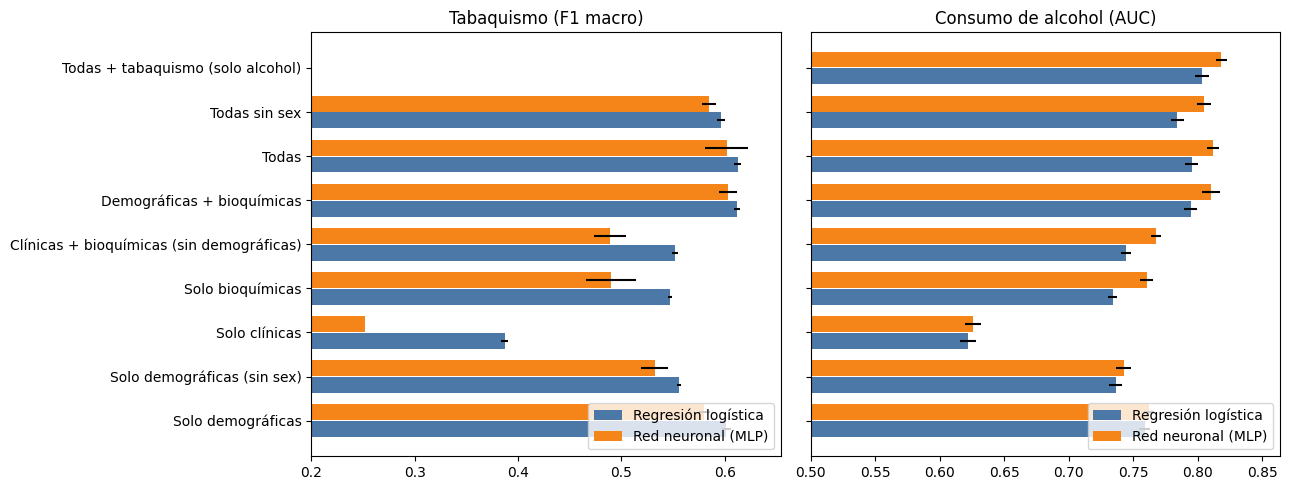

In [ ]:
tg = pd.DataFrame(resultados_grupos)
tg["valor"] = tg.apply(lambda f: f"{f['media']:.3f} ± {f['ic95']:.3f}", axis=1)
tabla_g = tg.pivot_table(index=["escenario", "n_variables"], columns=["tarea", "modelo"],
                         values="valor", aggfunc="first")
tabla_g = tabla_g.reindex([(e, v) for e in escenarios for v in sorted(tg[tg.escenario == e].n_variables.unique())])
print(tabla_g.to_string())
tg.to_csv(os.path.join("resultados_grupos.csv"), index=False)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
orden = list(escenarios)
for eje, (tarea, titulo) in zip(ejes, [("tabaco", "Tabaquismo (F1 macro)"), ("alcohol", "Consumo de alcohol (AUC)")]):
    for k, (mod, color) in enumerate([("Regresión logística", "#4c78a8"), ("Red neuronal (MLP)", "#f58518")]):
        d = tg[(tg.tarea == tarea) & (tg.modelo == mod)].set_index("escenario").reindex(orden).dropna(subset=["media"])
        eje.barh([orden.index(e) + (k - 0.5) * 0.38 for e in d.index], d["media"], xerr=d["ic95"],
                 height=0.36, label=mod, color=color)
    eje.set_title(titulo); eje.set_yticks(range(len(orden))); eje.set_yticklabels(orden)
    eje.invert_yaxis(); eje.set_xlim(0.2 if tarea == "tabaco" else 0.5, None); eje.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join("grupos_variables.png"), dpi=150)
plt.show()

## Fase #8: Análisis de variables y reducción de dimensión

Comparamos tres maneras de usar menos entradas: retirar siete variables, combinar las entradas con PCA y crear una representación con UMAP. Usamos el MLP y el bosque con los mismos cinco pliegues de la fase 6. Estas comparaciones se hacen en la muestra de ajuste. El conjunto de prueba se reserva para la fase 9.

### Fase #8.1: Análisis individual de variables

Revisamos qué señal da cada variable por sí sola con el AUC y la información mutua. También buscamos pares de variables muy correlacionadas con Spearman. Esto orienta la selección de candidatas. Para estimar qué pasa al quitar varias juntas, se necesita el ensayo de 8.2.2.

In [ ]:
filas = []
for c in X_tun.columns:
    v = X_tun[c].values
    a = roc_auc_score(ya_tun, v); a = max(a, 1 - a)
    t = [max(roc_auc_score((np.asarray(yt_tun) == k).astype(int), v),
             1 - roc_auc_score((np.asarray(yt_tun) == k).astype(int), v))
         for k in (1, 2, 3)]
    filas.append((c, a, *t))

ind = pd.DataFrame(filas, columns=["variable", "auc_alcohol",
                                   "auc_nunca", "auc_exfum", "auc_fuma"])
ind["mi_tabaco"]  = mutual_info_classif(X_tun, yt_tun, random_state=SEED)
ind["mi_alcohol"] = mutual_info_classif(X_tun, ya_tun, random_state=SEED)
ind = ind.sort_values("auc_alcohol", ascending=False).round(3)
print(ind.to_string(index=False))

# Pares muy correlacionados entre sí (|Spearman| >= 0.7)
C = X_tun.corr(method="spearman").abs().values.copy()
np.fill_diagonal(C, 0)
cols = X_tun.columns
pares = sorted([(cols[i], cols[j], round(C[i, j], 3))
                for i in range(len(cols)) for j in range(i + 1, len(cols))
                if C[i, j] >= 0.7], key=lambda p: -p[2])
print(pares)

ind.to_csv("analisis_individual.csv", index=False)

        variable  auc_alcohol  auc_nunca  auc_exfum  auc_fuma  mi_tabaco  mi_alcohol
          height        0.715      0.797      0.702     0.745      0.155       0.080
             sex        0.683      0.829      0.748     0.750      0.240       0.079
      hemoglobin        0.682      0.792      0.676     0.760      0.142       0.053
       gamma_GTP        0.670      0.737      0.646     0.709      0.087       0.047
             age        0.663      0.542      0.565     0.614      0.024       0.043
          weight        0.656      0.742      0.687     0.681      0.099       0.039
serum_creatinine        0.605      0.722      0.688     0.651      0.081       0.020
     sight_right        0.595      0.566      0.530     0.567      0.008       0.015
      sight_left        0.594      0.564      0.527     0.567      0.007       0.014
       waistline        0.573      0.678      0.656     0.617      0.053       0.010
             DBP        0.558      0.585      0.573     0.557    

### Fase #8.2: PCA

Exploramos cuánta varianza se conserva antes y después de recortar a ±5 rangos intercuartílicos. Para evaluar los modelos, ajustamos el escalador y PCA dentro de cada pliegue con un `Pipeline`. Probamos 6, 10, 14 y 18 componentes con los hiperparámetros de la fase 6. Usamos el intervalo de la línea base como referencia práctica para escoger un tamaño. El MLP quedó cerca de su línea base con 18 componentes. Los tamaños evaluados quedaron por debajo de esa referencia para el bosque.

== RobustScaler ==
Varianza comp. 1-5: [0.366 0.141 0.094 0.077 0.055]
Componentes para 90 %: 10 | 95 %: 12 | 99 %: 17
Comp. 1, mayores cargas: {'SGOT_AST': 0.6, 'gamma_GTP': 0.54, 'SGOT_ALT': 0.54, 'triglyceride': 0.13}
Comp. 2, mayores cargas: {'gamma_GTP': 0.7, 'SGOT_AST': 0.44, 'SGOT_ALT': 0.4, 'BLDS': 0.24}
Últimos 4 autovalores: [0.0138 0.0076 0.0035 0.0024]
== RobustScaler + recorte ±5 ==
Varianza comp. 1-5: [0.3   0.106 0.104 0.081 0.066]
Componentes para 90 %: 11 | 95 %: 14 | 99 %: 18
Comp. 1, mayores cargas: {'gamma_GTP': 0.5, 'SGOT_ALT': 0.46, 'SGOT_AST': 0.4, 'triglyceride': 0.27}
Comp. 2, mayores cargas: {'SGOT_AST': 0.48, 'weight': 0.39, 'height': 0.32, 'hemoglobin': 0.27}
Últimos 4 autovalores: [0.0138 0.0069 0.0035 0.0024]


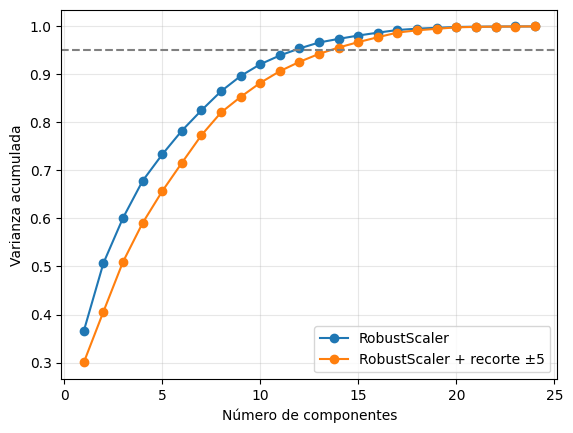

In [ ]:
# Primero exploramos sin modelo
Z0 = RobustScaler().fit_transform(X_tun)      # solo con X_tun (entrenamiento)
Z1 = np.clip(Z0, -5, 5)                       # recorte a ±5 IQR (juicio)

curvas = {}
for nombre, Z in [("RobustScaler", Z0), ("RobustScaler + recorte ±5", Z1)]:
    p = PCA(random_state=SEED).fit(Z)
    cum = np.cumsum(p.explained_variance_ratio_)
    curvas[nombre] = cum
    print("==", nombre, "==")
    print("Varianza comp. 1-5:", p.explained_variance_ratio_[:5].round(3))
    print("Componentes para 90 %:", int((cum < 0.90).sum() + 1),
          "| 95 %:", int((cum < 0.95).sum() + 1),
          "| 99 %:", int((cum < 0.99).sum() + 1))
    for k in (0, 1):
        print(f"Comp. {k+1}, mayores cargas:",
              pd.Series(p.components_[k], index=X_tun.columns).abs()
              .sort_values(ascending=False).head(4).round(2).to_dict())
    print("Últimos 4 autovalores:", p.explained_variance_[-4:].round(4))

for nombre, cum in curvas.items():
    plt.plot(range(1, len(cum) + 1), cum, marker="o", label=nombre)
plt.axhline(0.95, ls="--", c="gray")
plt.xlabel("Número de componentes"); plt.ylabel("Varianza acumulada")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
def recortar(Z):
    return np.clip(Z, -5, 5)          # recorte fijo en unidades de IQR (juicio)

def params_modelo(nombre, tarea):
    # quita el prefijo "modelo__" para usarlos sobre el modelo solo
    return {k.replace("modelo__", ""): v for k, v in mejores[(nombre, tarea)].items()}

def modelo_base(nombre, tarea):
    p = params_modelo(nombre, tarea)
    if nombre == "Random forest":
        m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
    else:
        m = MLPClassifier(early_stopping=True, n_iter_no_change=5, max_iter=100, random_state=SEED)
    return m.set_params(**p)

def pipe_pca(modelo, k):
    return Pipeline([("escalado", RobustScaler()),
                     ("recorte", FunctionTransformer(recortar)),
                     ("pca", PCA(n_components=k, random_state=SEED)),
                     ("modelo", modelo)])

def cv_ic(modelo, X, y, scoring):
    s = cross_val_score(modelo, X, y, cv=pliegues, scoring=scoring, n_jobs=1)
    return s.mean(), 2.776 * s.std(ddof=1) / np.sqrt(len(s))   # t de Student, 4 g.l.

# Verifica que los hiperparámetros se leyeron bien (que no sean cadenas)
for clave in [("Random forest", "tabaco"), ("Red neuronal (MLP)", "alcohol")]:
    print(clave, mejores[clave])

K_LISTA = [6, 10, 14, 18]
RUTA_RED = "/content/resultados_reduccion.json"
resultados_reduccion = []


('Random forest', 'tabaco') {'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}
('Red neuronal (MLP)', 'alcohol') {'modelo__alpha': 1.0053940194693018e-05, 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': 0.00023270677083837802}


In [ ]:
#Ahora si, buscamos que componentes con random forest y redes neuronales
def recortar(Z):
    return np.clip(Z, -5, 5)          # recorte fijo en unidades de IQR (juicio)

def params_modelo(nombre, tarea):
    # quita el prefijo "modelo__" para usarlos sobre el modelo solo
    return {k.replace("modelo__", ""): v for k, v in mejores[(nombre, tarea)].items()}

def modelo_base(nombre, tarea):
    p = params_modelo(nombre, tarea)
    if nombre == "Random forest":
        m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
    else:
        m = MLPClassifier(early_stopping=True, n_iter_no_change=5, max_iter=100, random_state=SEED)
    return m.set_params(**p)

def pipe_pca(modelo, k):
    return Pipeline([("escalado", RobustScaler()),
                     ("recorte", FunctionTransformer(recortar)),
                     ("pca", PCA(n_components=k, random_state=SEED)),
                     ("modelo", modelo)])

def cv_ic(modelo, X, y, scoring):
    s = cross_val_score(modelo, X, y, cv=pliegues, scoring=scoring, n_jobs=1)
    return s.mean(), 2.776 * s.std(ddof=1) / np.sqrt(len(s))   # t de Student, 4 g.l.

# Verifica que los hiperparámetros se leyeron bien (que no sean cadenas)
for clave in [("Random forest", "tabaco"), ("Red neuronal (MLP)", "alcohol")]:
    print(clave, mejores[clave])

K_LISTA = [6, 10, 14, 18]
RUTA_RED = "/content/resultados_reduccion.json"
resultados_reduccion = []

for nombre in ["Red neuronal (MLP)", "Random forest"]:
    for tarea in ["tabaco", "alcohol"]:
        y, sc = (yt_tun, "f1_macro") if tarea == "tabaco" else (ya_tun, "roc_auc")
        base = [r for r in resultados_busqueda if r["modelo"] == nombre and r["tarea"] == tarea][0]
        print(f"\n== {nombre} | {tarea} | sin PCA (24 vars): {base['media']:.3f} ± {base['ic95']:.3f}")
        for k in K_LISTA:
            t = time.time()
            m, ic = cv_ic(pipe_pca(modelo_base(nombre, tarea), k), X_tun, y, sc)
            seg = time.time() - t
            resultados_reduccion.append({"etapa": "k", "modelo": nombre, "tarea": tarea,
                                         "k": k, "media": m, "ic95": ic, "segundos": round(seg, 1)})
            print(f"   k={k:2d}: {m:.3f} ± {ic:.3f}  ({seg:.0f} s)")
        json.dump(resultados_reduccion, open(RUTA_RED, "w"))   # guarda tras cada modelo/tarea

('Random forest', 'tabaco') {'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}
('Red neuronal (MLP)', 'alcohol') {'modelo__alpha': 1.0053940194693018e-05, 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': 0.00023270677083837802}

== Red neuronal (MLP) | tabaco | sin PCA (24 vars): 0.605 ± 0.006
   k= 6: 0.483 ± 0.019  (80 s)
   k=10: 0.558 ± 0.021  (82 s)
   k=14: 0.595 ± 0.007  (91 s)
   k=18: 0.599 ± 0.011  (75 s)

== Red neuronal (MLP) | alcohol | sin PCA (24 vars): 0.812 ± 0.004
   k= 6: 0.752 ± 0.007  (89 s)
   k=10: 0.795 ± 0.005  (79 s)
   k=14: 0.805 ± 0.006  (77 s)
   k=18: 0.811 ± 0.006  (109 s)

== Random forest | tabaco | sin PCA (24 vars): 0.618 ± 0.003
   k= 6: 0.544 ± 0.004  (268 s)
   k=10: 0.577 ± 0.006  (431 s)
   k=14: 0.594 ± 0.006  (620 s)
   k=18: 0.601 ± 0.005  (766 s)

== Random forest | alcohol | sin PCA (24 vars): 0.808 ± 0.005
   k= 6: 0.743 ± 0.007  (244 s)
   k=10: 0.782 ± 0.006  (375 s)
   k=14: 0.790 ± 

#### Fase #8.2.1: Reajuste del MLP con PCA de 18 componentes

Repetimos la búsqueda de ocho configuraciones del MLP ya en el espacio reducido. Los resultados se guardan en `resultados_reduccion_pca.json`. Este reajuste se realizó para el MLP con PCA de 18 componentes.

In [ ]:
K_MLP = 18
RUTA_PCA = "/content/resultados_reduccion_pca.json"
resultados_pca = []

def buscar_pca(nombre, tarea, k, modelo, espacio, n_iter=N_ITER):
    y = yt_tun if tarea == "tabaco" else ya_tun
    scoring = "f1_macro" if tarea == "tabaco" else "roc_auc"
    bus = RandomizedSearchCV(pipe_pca(modelo, k), espacio, n_iter=n_iter, scoring=scoring,
                             cv=pliegues, random_state=SEED, n_jobs=1, refit=False)
    t = time.time(); bus.fit(X_tun, y); seg = time.time() - t
    r = pd.DataFrame(bus.cv_results_).sort_values("rank_test_score")
    m = r.iloc[0]; n = len(pliegues)
    s = m["std_test_score"] * np.sqrt(n / (n - 1))
    ic = 2.776 * s / np.sqrt(n)
    resultados_pca.append({"etapa": "reajuste", "modelo": nombre, "tarea": tarea, "k": k,
                           "metrica": scoring, "media": float(m["mean_test_score"]), "ic95": float(ic),
                           "params": {p: (v if isinstance(v, (str, int, float, tuple, type(None))) else float(v))
                                      for p, v in m["params"].items()},
                           "segundos": round(seg, 1)})
    json.dump(resultados_pca, open(RUTA_PCA, "w"), indent=1, default=str)
    print(f"{nombre} | {tarea} | k={k} | {scoring} = {m['mean_test_score']:.3f} ± {ic:.3f} | "
          f"{seg/60:.1f} min | {m['params']}")

for tarea in ("tabaco", "alcohol"):
    buscar_pca("Red neuronal (MLP)", tarea, K_MLP,
               MLPClassifier(early_stopping=True, n_iter_no_change=5, max_iter=100, random_state=SEED),
               {"modelo__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (64, 32, 16)],
                "modelo__alpha": loguniform(1e-5, 1e-2),
                "modelo__learning_rate_init": loguniform(1e-4, 1e-2)})

Red neuronal (MLP) | tabaco | k=18 | f1_macro = 0.599 ± 0.011 | 7.6 min | {'modelo__alpha': np.float64(0.008123245085588688), 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': np.float64(0.007535384509295544)}
Red neuronal (MLP) | alcohol | k=18 | roc_auc = 0.813 ± 0.004 | 6.9 min | {'modelo__alpha': np.float64(0.008123245085588688), 'modelo__hidden_layer_sizes': (128, 64), 'modelo__learning_rate_init': np.float64(0.007535384509295544)}


#### Fase #8.2.2: Selección de 17 variables

Retiramos siete candidatas y comparamos con las 24 entradas originales sin cambiar los hiperparámetros. La elección de las variables y la comparación usan la muestra de ajuste, así que esta es una comparación exploratoria. Se guarda en `/content/resultados_sin_candidatas.json`.

In [ ]:
CAND = ["tot_chole", "LDL_chole", "urine_protein", "hear_left", "hear_right",
        "sight_left_cod", "sight_right_cod"]
X_sel = X_tun.drop(columns=CAND)
print(X_sel.shape)

resultados_sel = []
for nombre in ["Red neuronal (MLP)", "Random forest"]:
    for tarea in ["tabaco", "alcohol"]:
        y, sc = (yt_tun, "f1_macro") if tarea == "tabaco" else (ya_tun, "roc_auc")
        m = modelo_base(nombre, tarea)
        if nombre != "Random forest":
            m = con_escalado(m)
        t = time.time()
        media, ic = cv_ic(m, X_sel, y, sc)
        base = [r for r in resultados_busqueda if r["modelo"] == nombre and r["tarea"] == tarea][0]
        resultados_sel.append({"etapa": "sin_candidatas", "modelo": nombre, "tarea": tarea,
                               "n_vars": X_sel.shape[1], "media": media, "ic95": ic,
                               "segundos": round(time.time() - t, 1)})
        print(f"{nombre} | {tarea} | 17 vars: {media:.3f} ± {ic:.3f} | "
              f"24 vars (fase 6): {base['media']:.3f} ± {base['ic95']:.3f}")

json.dump(resultados_sel, open("/content/resultados_sin_candidatas.json", "w"), indent=1)

(100000, 17)
Red neuronal (MLP) | tabaco | 17 vars: 0.602 ± 0.012 | 24 vars (fase 6): 0.605 ± 0.006
Red neuronal (MLP) | alcohol | 17 vars: 0.811 ± 0.004 | 24 vars (fase 6): 0.812 ± 0.004
Random forest | tabaco | 17 vars: 0.616 ± 0.003 | 24 vars (fase 6): 0.618 ± 0.003
Random forest | alcohol | 17 vars: 0.807 ± 0.005 | 24 vars (fase 6): 0.808 ± 0.005


### Fase #8.3: UMAP

Probamos 10 dimensiones, 15 vecinos y distancia mínima 0. Ajustamos la representación con los datos de entrenamiento de cada pliegue y transformamos los de validación con ese mismo UMAP. La primera celda es un piloto de tiempo y la segunda produce los resultados de los cinco pliegues para el MLP y el bosque con los hiperparámetros previos.

Cada ejecución crea una carpeta temporal para guardar los embeddings por pliegue y compartirlos entre los dos modelos.

In [ ]:
tr, va = pliegues[0]
pre = Pipeline([("escalado", RobustScaler()), ("recorte", FunctionTransformer(recortar))])
Ztr = pre.fit_transform(X_tun.iloc[tr]); Zva = pre.transform(X_tun.iloc[va])

# calentamiento: la primera llamada compila código y distorsiona el tiempo
umap.UMAP(n_components=10, random_state=SEED).fit_transform(Ztr[:3000])

t = time.time()
um = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0, random_state=SEED)
Etr = um.fit_transform(Ztr)
t_fit = time.time() - t

t = time.time(); Eva = um.transform(Zva); t_tr = time.time() - t

mlp = MLPClassifier(early_stopping=True, n_iter_no_change=5, max_iter=100, random_state=SEED,
                    **params_modelo("Red neuronal (MLP)", "alcohol")).fit(Etr, ya_tun.iloc[tr])
auc = roc_auc_score(ya_tun.iloc[va], mlp.predict_proba(Eva)[:, 1])
print(f"fit {t_fit/60:.1f} min | transform {t_tr/60:.1f} min | AUC alcohol (1 pliegue, k=10): {auc:.3f}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


fit 3.6 min | transform 1.8 min | AUC alcohol (1 pliegue, k=10): 0.755


In [ ]:
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

from tempfile import TemporaryDirectory

cache_umap = TemporaryDirectory(prefix="embeddings_umap_", dir="/content")
CARPETA_EMB = cache_umap.name + "/"
pre = Pipeline([("escalado", RobustScaler()), ("recorte", FunctionTransformer(recortar))])

def embeddings_umap(k, n_neighbors=15, min_dist=0.0):
    for f, (tr, va) in enumerate(pliegues):
        ruta = f"{CARPETA_EMB}umap_k{k}_f{f}.npz"
        if os.path.exists(ruta):
            continue
        t = time.time()
        Ztr = pre.fit_transform(X_tun.iloc[tr]); Zva = pre.transform(X_tun.iloc[va])
        um = umap.UMAP(n_components=k, n_neighbors=n_neighbors, min_dist=min_dist, random_state=SEED)
        Etr = um.fit_transform(Ztr); Eva = um.transform(Zva)
        seg = time.time() - t
        np.savez_compressed(ruta, Etr=Etr, Eva=Eva, seg=seg)
        print(f"k={k} pliegue {f+1}/5: {seg/60:.1f} min")

def evaluar_umap(nombre, tarea, k):
    y = yt_tun if tarea == "tabaco" else ya_tun
    puntajes = []
    for f, (tr, va) in enumerate(pliegues):
        d = np.load(f"{CARPETA_EMB}umap_k{k}_f{f}.npz")
        m = modelo_base(nombre, tarea)
        if nombre != "Random forest":
            m = con_escalado(m)
        m.fit(d["Etr"], y.iloc[tr]); p = m.predict_proba(d["Eva"])
        if tarea == "tabaco":
            puntajes.append(f1_score(y.iloc[va], m.classes_[p.argmax(1)], average="macro"))
        else:
            puntajes.append(roc_auc_score(y.iloc[va], p[:, 1]))
    puntajes = np.array(puntajes)
    return puntajes.mean(), 2.776 * puntajes.std(ddof=1) / np.sqrt(len(puntajes))

umap.UMAP(n_components=10, random_state=SEED).fit_transform(np.random.rand(3000, 24))

embeddings_umap(10)

resultados_umap = []
for nombre in ["Red neuronal (MLP)", "Random forest"]:
    for tarea in ["tabaco", "alcohol"]:
        t = time.time(); media, ic = evaluar_umap(nombre, tarea, 10)
        resultados_umap.append({"etapa": "umap_k", "modelo": nombre, "tarea": tarea, "k": 10,
                                "media": media, "ic95": ic, "segundos": round(time.time() - t, 1)})
        print(f"{nombre} | {tarea} | UMAP k=10: {media:.3f} ± {ic:.3f}")
json.dump(resultados_umap, open("/content/resultados_umap.json", "w"), indent=1)

k=10 pliegue 1/5: 3.7 min
k=10 pliegue 2/5: 2.6 min
k=10 pliegue 3/5: 2.5 min
k=10 pliegue 4/5: 3.1 min
k=10 pliegue 5/5: 2.4 min
Red neuronal (MLP) | tabaco | UMAP k=10: 0.532 ± 0.011
Red neuronal (MLP) | alcohol | UMAP k=10: 0.762 ± 0.006
Random forest | tabaco | UMAP k=10: 0.571 ± 0.002
Random forest | alcohol | UMAP k=10: 0.759 ± 0.005


## Fase #9: Evaluación final en el conjunto de prueba

Reentrenamos los cinco modelos independientes con su configuración seleccionada y las 24 variables. Usamos las 198.201 filas reservadas desde la fase 2. Reportamos la métrica principal de cada tarea y un IC95 % obtenido con 200 remuestreos de etiquetas y predicciones. Para describir el ajuste, calculamos también la métrica sobre 20.000 filas del conjunto que vio el modelo durante el entrenamiento.

Ejecuta primero la celda que define `final` e inicializa `tabla_test`. Luego ejecuta 9.1 y 9.2. El CSV queda en `/content/resultados_final_prueba.csv` con diez filas. Si repites un bloque en la misma sesión, se actualiza la fila de cada par de modelo y tarea.

In [ ]:
def construir(nombre, tarea):
    if nombre == "Regresión logística": m = con_escalado(LogisticRegression(max_iter=1000))
    elif nombre == "Random forest":     m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
    elif nombre == "KNN":               m = con_escalado(KNeighborsClassifier(n_jobs=-1))
    elif nombre == "Red neuronal (MLP)":
        m = con_escalado(MLPClassifier(early_stopping=True, n_iter_no_change=5, max_iter=100, random_state=SEED))
    elif nombre == "SVM RBF":           m = con_escalado(SVC(kernel="rbf", probability=True, random_state=SEED))
    return m.set_params(**mejores[(nombre, tarea)])

def principal(y, proba, tarea, clases):
    y = np.asarray(y)
    if tarea == "tabaco":
        return f1_score(y, clases[proba.argmax(axis=1)], average="macro")
    return roc_auc_score(y, proba[:, 1])

def ic_bootstrap(y, proba, tarea, clases, B=200):
    rng = np.random.RandomState(SEED); n = len(y); v = []
    for _ in range(B):
        i = rng.randint(0, n, n)
        v.append(principal(np.asarray(y)[i], proba[i], tarea, clases))
    return np.percentile(v, [2.5, 97.5])

tabla_test = {}
def final(nombre, tarea, X_fit, y_fit):
    y_te = yt_test if tarea == "tabaco" else ya_test
    m = construir(nombre, tarea)
    t = time.time(); m.fit(X_fit, y_fit); seg = time.time() - t
    clases = m.classes_
    i = np.random.RandomState(SEED).choice(len(X_fit), min(20000, len(X_fit)), replace=False)
    p_tr = m.predict_proba(X_fit.iloc[i]); m_tr = principal(np.asarray(y_fit)[i], p_tr, tarea, clases)
    p_te = m.predict_proba(X_test)
    if tarea == "tabaco":
        res, por_clase = evaluar_tabaco(y_te, clases[p_te.argmax(axis=1)], p_te)
    else:
        res = evaluar_alcohol(y_te, (p_te[:, 1] >= 0.5).astype(int), p_te[:, 1]); por_clase = None
    lo, hi = ic_bootstrap(y_te, p_te, tarea, clases)
    tabla_test[(nombre, tarea)] = {
        "modelo": nombre, "tarea": tarea, "n_entrenamiento": len(X_fit),
        "metrica_principal_entrenamiento": m_tr, "IC95_prueba_inf": lo, "IC95_prueba_sup": hi,
        **res, "segundos": round(seg, 1),
    }
    print(f"{nombre} | {tarea} | entrenamiento {m_tr:.3f} | prueba {principal(y_te, p_te, tarea, clases):.3f} "
          f"[{lo:.3f}, {hi:.3f}] | {seg/60:.1f} min")
    if por_clase is not None: print(por_clase.round(3))
    pd.DataFrame(list(tabla_test.values())).to_csv("/content/resultados_final_prueba.csv", index=False)

### Fase #9.1: Regresión logística, MLP y bosque aleatorio

Entrenamos los tres modelos con las 792.804 filas, una vez por tarea. La ejecución registra seis filas.

In [ ]:
for nombre in ["Regresión logística", "Red neuronal (MLP)", "Random forest"]:
    for tarea in ["tabaco", "alcohol"]:
        final(nombre, tarea, X_ent, yt_ent if tarea == "tabaco" else ya_ent)

Regresión logística | tabaco | entrenamiento 0.617 | prueba 0.612 [0.610, 0.614] | 1.3 min
             precision  sensibilidad     F1
1 nunca          0.943         0.725  0.819
2 exfumador      0.404         0.614  0.488
3 fuma           0.480         0.590  0.529
Regresión logística | alcohol | entrenamiento 0.799 | prueba 0.795 [0.793, 0.797] | 0.1 min
Red neuronal (MLP) | tabaco | entrenamiento 0.600 | prueba 0.596 [0.594, 0.599] | 5.6 min
             precision  sensibilidad     F1
1 nunca          0.832         0.833  0.833
2 exfumador      0.442         0.376  0.407
3 fuma           0.520         0.584  0.550
Red neuronal (MLP) | alcohol | entrenamiento 0.821 | prueba 0.816 [0.814, 0.817] | 3.3 min
Random forest | tabaco | entrenamiento 0.847 | prueba 0.620 [0.618, 0.622] | 11.2 min
             precision  sensibilidad     F1
1 nunca          0.928         0.744  0.826
2 exfumador      0.420         0.543  0.473
3 fuma           0.492         0.649  0.560
Random forest | alcoho

### Fase #9.2: KNN y SVM

KNN usa la muestra de 100.000 registros y la SVM se ajusta con 20.000. En prueba, la SVM usa probabilidades y elige la clase de mayor probabilidad para tabaquismo. En la búsqueda de la fase 6 se usó su regla de decisión para F1 macro y su puntaje de decisión para el AUC. Esta sección agrega las cuatro filas restantes al CSV.

In [ ]:
X_sv, yt_sv, ya_sv, _ = submuestra_de(X_ent, yt_ent, ya_ent, Y_ind_ent, 20_000)
for tarea in ["tabaco", "alcohol"]:
    final("KNN", tarea, X_tun, yt_tun if tarea == "tabaco" else ya_tun)
for tarea in ["tabaco", "alcohol"]:
    final("SVM RBF", tarea, X_sv, yt_sv if tarea == "tabaco" else ya_sv)

KNN | tabaco | entrenamiento 1.000 | prueba 0.562 [0.559, 0.564] | 0.0 min
             precision  sensibilidad     F1
1 nunca          0.797         0.841  0.818
2 exfumador      0.429         0.300  0.353
3 fuma           0.493         0.537  0.514
KNN | alcohol | entrenamiento 1.000 | prueba 0.792 [0.790, 0.793] | 0.0 min
SVM RBF | tabaco | entrenamiento 0.607 | prueba 0.576 [0.574, 0.578] | 2.3 min
             precision  sensibilidad     F1
1 nunca          0.791         0.845  0.817
2 exfumador      0.440         0.347  0.388
3 fuma           0.527         0.518  0.522
SVM RBF | alcohol | entrenamiento 0.817 | prueba 0.805 [0.803, 0.807] | 2.3 min
